In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import binom, poisson, norm

# Dublin Fire Brigade (DFB) and Ambulance (DA) annual incident activity logs (2025)

Fields include incident date, district/area information, and response time data. The fields from MOB through to CD are generated automatically by the vehicle system (either via button press or voice message) and reflect the vehicle’s operational status throughout an incident lifecycle:

* **TOC** – Time the call is received in the control centre
* **ORD** – Time when first vehicle is ordered/mobilised to the incident
* **MOB** – Time when first vehicle becomes mobile to the incident
* **IA** – Time when first vehicle arrives at the incident scene
* **LS** – Leaving scene; time when first ambulance departs for hospital
* **AH** – Arrival time at hospital of first appliance or ambulance
* **MAV** – Time when first vehicle is mobile and available again
* **CD** – Time when last vehicle closes down/back at station-Incident Closure

## Incident priority categories:

* **Echo** – Life-threatening cardiac or respiratory arrest
* **Delta** – Life-threatening incident other than cardiac or respiratory arrest
* **Charlie** – Serious, not life-threatening, immediate response required
* **Bravo** – Serious, not life-threatening, urgent response
* **Alpha** – Non-serious or non-life-threatening incident
* **Omega** – Minor illness or injury

In [2]:
df = pd.read_csv('dfb-ambulance-incidents-2025.csv')
df.head()

,ID,Date,Stat IDS with Stn Name DUB_Station Area,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD
0,1,01/01/2025,Kilbarrack Fire Station,D,00:01:21,00:06:36,00:09:24,NaN,NaN,00:54:48,01:58:40,01:58:49
1,2,01/01/2025,Finglas Fire Station,B,00:06:07,00:28:06,00:30:02,NaN,NaN,NaN,00:31:21,00:39:41
2,3,01/01/2025,Swords Fire Station,C,00:09:05,00:34:53,00:37:11,00:53:55,01:18:35,01:37:21,01:46:15,01:47:43
3,4,01/01/2025,Tara Street Fire Station,D,00:12:08,00:18:16,00:18:55,00:22:54,00:35:46,00:37:16,NaN,01:21:23
4,5,01/01/2025,Tallaght Fire Station,D,00:15:47,00:20:04,00:22:14,NaN,NaN,NaN,00:45:21,00:45:33


The name on one of the columns seems to be very long, we are going to shorten it.

In [3]:
df.rename(columns={"Stat IDS with Stn Name DUB_Station Area": "Station"}, inplace=True)
df.head()

,ID,Date,Station,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD
0,1,01/01/2025,Kilbarrack Fire Station,D,00:01:21,00:06:36,00:09:24,NaN,NaN,00:54:48,01:58:40,01:58:49
1,2,01/01/2025,Finglas Fire Station,B,00:06:07,00:28:06,00:30:02,NaN,NaN,NaN,00:31:21,00:39:41
2,3,01/01/2025,Swords Fire Station,C,00:09:05,00:34:53,00:37:11,00:53:55,01:18:35,01:37:21,01:46:15,01:47:43
3,4,01/01/2025,Tara Street Fire Station,D,00:12:08,00:18:16,00:18:55,00:22:54,00:35:46,00:37:16,NaN,01:21:23
4,5,01/01/2025,Tallaght Fire Station,D,00:15:47,00:20:04,00:22:14,NaN,NaN,NaN,00:45:21,00:45:33


## Preparing and Cleaning the Data

Get info of the data and check for null values

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 83233 entries, 0 to 83232
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID           83233 non-null  int64
 1   Date         83233 non-null  str  
 2   Station      83233 non-null  str  
 3   criticality  83233 non-null  str  
 4   TOC          83233 non-null  str  
 5   ORD          83233 non-null  str  
 6   MOB          81891 non-null  str  
 7   IA           72729 non-null  str  
 8   LS           54199 non-null  str  
 9   AH           55530 non-null  str  
 10  MAV          77238 non-null  str  
 11  CD           83233 non-null  str  
dtypes: int64(1), str(11)
memory usage: 14.9 MB


In [5]:
df.isnull().sum()

ID                 0
Date               0
Station            0
criticality        0
TOC                0
ORD                0
MOB             1342
IA             10504
LS             29034
AH             27703
MAV             5995
CD                 0
dtype: int64

### Missing Values

Seven columns have no gaps (ID, Date, Station, Criticality, TOC, ORD and CD). Before we handle any missing values, lets get the count (%) on how many values are missing.

In [6]:
time_cols = ["MOB", "IA", "LS", "AH", "MAV"]
missing = pd.DataFrame({
    "Missing": df[time_cols].isnull().sum(),
    "% missing": (df[time_cols].isnull().mean() * 100).round(1),
}).sort_values("% missing", ascending=False)
missing

,Missing,% missing
LS,29034,34.9
AH,27703,33.3
IA,10504,12.6
MAV,5995,7.2
MOB,1342,1.6


As we can see, there's lots of missing values on the time columns. Therefore, dropping all of the rows with null values will result on a bias. We will keep every row and only filter missing values only if we analyse the respective variable.

### Formatting Date Column

One of the things we can notice is that the **Date** column is set as a string. It's better if we cast it as a date using Pandas.

In [7]:
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df.dtypes

ID                      int64
Date           datetime64[us]
Station                   str
criticality               str
TOC                       str
ORD                       str
MOB                       str
IA                        str
LS                        str
AH                        str
MAV                       str
CD                        str
dtype: object

### Encoding ordinal data

Since the **criticality** may be considered as a categorical, ordinal feature, we might as well encode it.

In [8]:
criticality_values = {
  "E": 5,
  "D": 4,
  "C": 3,
  "B": 2,
  "A": 1,
  "O": 0
}
df["criticality_encoded"] = df["criticality"].map(criticality_values)
df.head()

,ID,Date,Station,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD,criticality_encoded
0,1,2025-01-01,Kilbarrack Fire Station,D,00:01:21,00:06:36,00:09:24,NaN,NaN,00:54:48,01:58:40,01:58:49,4
1,2,2025-01-01,Finglas Fire Station,B,00:06:07,00:28:06,00:30:02,NaN,NaN,NaN,00:31:21,00:39:41,2
2,3,2025-01-01,Swords Fire Station,C,00:09:05,00:34:53,00:37:11,00:53:55,01:18:35,01:37:21,01:46:15,01:47:43,3
3,4,2025-01-01,Tara Street Fire Station,D,00:12:08,00:18:16,00:18:55,00:22:54,00:35:46,00:37:16,NaN,01:21:23,4
4,5,2025-01-01,Tallaght Fire Station,D,00:15:47,00:20:04,00:22:14,NaN,NaN,NaN,00:45:21,00:45:33,4


## Getting more from the existing data

Since most of the columns provide useful time data, we might as well get some other information into the dataset. We will reuse a function to calcute the minutes between two times.

In [9]:
def minutes_between(start, end):
    diff = (pd.to_timedelta(df[end]) - pd.to_timedelta(df[start])).dt.total_seconds() / 60
    crossed_midnight = diff < -60
    diff[crossed_midnight] += 24 * 60

    # end logged seconds before start
    clock_error = (diff < 0) & ~crossed_midnight
    diff[clock_error] = np.nan

    return diff

### Dispatch Delay

$ORD - TOC$

* **ORD** Time when first vehicle is ordered/mobilised to the incident
* **TOC** Time of call


In [10]:
df["dispatch_delay"] = minutes_between("TOC", "ORD")

### Travel Time

$IA - MOB$

* **IA** – Time when first vehicle arrives at the incident scene
* **MOB** – Time when first vehicle becomes mobile to the incident


In [11]:
df["travel_time"] = minutes_between("MOB", "IA")

### Response Time

$IA - TOC$

* **IA** – Time when first vehicle arrives at the incident scene
* **TOC** – Time the call is received in the control centre

In [12]:
df["response_time"] = minutes_between("TOC", "IA")

### Job Duration

$TOC - CD$

* **TOC** – Time the call is received in the control centre
* **CD** – Time when last vehicle closes down/back at station-Incident Closure

In [13]:
df["job_duration"] = minutes_between("TOC", "CD")

In [14]:
df.head()

,ID,Date,Station,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD,criticality_encoded,dispatch_delay,travel_time,response_time,job_duration
0,1,2025-01-01,Kilbarrack Fire Station,D,00:01:21,00:06:36,00:09:24,NaN,NaN,00:54:48,01:58:40,01:58:49,4,5.250000,NaN,NaN,117.466667
1,2,2025-01-01,Finglas Fire Station,B,00:06:07,00:28:06,00:30:02,NaN,NaN,NaN,00:31:21,00:39:41,2,21.983333,NaN,NaN,33.566667
2,3,2025-01-01,Swords Fire Station,C,00:09:05,00:34:53,00:37:11,00:53:55,01:18:35,01:37:21,01:46:15,01:47:43,3,25.800000,16.733333,44.833333,98.633333
3,4,2025-01-01,Tara Street Fire Station,D,00:12:08,00:18:16,00:18:55,00:22:54,00:35:46,00:37:16,NaN,01:21:23,4,6.133333,3.983333,10.766667,69.250000
4,5,2025-01-01,Tallaght Fire Station,D,00:15:47,00:20:04,00:22:14,NaN,NaN,NaN,00:45:21,00:45:33,4,4.283333,NaN,NaN,29.766667


## Task 1: Dataset Summary

### Categorical Data

We have two columns with categorical data: Station and Criticality

In [15]:
criticality_frequency = pd.DataFrame({
    "Count": df["criticality_encoded"].value_counts(),
    "Percentage": (df["criticality_encoded"].value_counts(normalize=True) * 100).round(2),
})
station_frequency = pd.DataFrame({
    "Count": df["Station"].value_counts(),
    "Percentage": (df["Station"].value_counts(normalize=True) * 100).round(2),
})

display(criticality_frequency)
display(station_frequency)

,Count,Percentage
criticality_encoded,,
4,40052,48.12
1,13913,16.72
3,13211,15.87
2,12061,14.49
5,2044,2.46
0,1952,2.35


,Count,Percentage
Station,,
Tallaght Fire Station,14040,16.87
Tara Street Fire Station,10963,13.17
Kilbarrack Fire Station,9171,11.02
Dolphins Barn Fire Station,8763,10.53
Phibsborough Fire Station,8710,10.46
Finglas Fire Station,7614,9.15
Rathfarnharm Fire Station,5060,6.08
Blanchardstown Fire Station,4983,5.99
North Strand Fire Station,4272,5.13


In [16]:
station_priority_pct = pd.crosstab(
  df["Station"],
  df["criticality_encoded"],
  normalize="index"
).mul(100).round(2)

display(station_priority_pct)

criticality_encoded,0,1,2,3,4,5
Station,,,,,,
Balbriggan Fire Station,2.24,15.43,16.87,18.23,44.84,2.40
Blanchardstown Fire Station,2.43,18.98,13.04,17.36,45.94,2.25
Dolphins Barn Fire Station,2.42,18.22,13.53,15.61,47.88,2.33
Donnybrook Fire Station,2.65,20.13,15.82,15.34,43.81,2.26
Dun Laoghaire Fire Station,1.47,13.27,22.42,6.78,43.66,12.39
Finglas Fire Station,2.88,18.20,14.45,16.39,45.88,2.21
Kilbarrack Fire Station,2.16,14.32,14.63,17.41,48.97,2.51
North Strand Fire Station,2.53,17.98,14.65,14.84,47.89,2.11
Phibsborough Fire Station,2.37,18.09,14.71,14.45,48.00,2.38


Given the Incident priority categories:

* **Echo (5)** – Life-threatening cardiac or respiratory arrest
* **Delta (4)** – Life-threatening incident other than cardiac or respiratory arrest
* **Charlie (3)** – Serious, not life-threatening, immediate response required
* **Bravo (2)** – Serious, not life-threatening, urgent response
* **Alpha (1)** – Non-serious or non-life-threatening incident
* **Omega (0)** – Minor illness or injury

We can safely assume that most incidents are of priority *Delta*, followed by *Alpha*, meaning that calls are either a life-threatening emergency or a non-serious incident. Most calls come from *Tallaght Station* and *Tara Street Fire Station* respectively. *Dún Laoghaire* has the least incidents, with only 339 incidents recorded.

### Numerical Data

We are going to use the new columns: Response Time, Dispatch Delay and Travel Time to get some insights on the time data.

In [17]:
# Useful statitstics for numerical data
time_stats = df[["response_time", "dispatch_delay", "travel_time"]].describe().round(2)
display(time_stats)

,response_time,dispatch_delay,travel_time
count,72727.00,83228.00,71768.00
mean,51.76,40.16,11.21
std,64.11,64.34,13.90
min,0.40,0.20,0.00
25%,15.43,5.25,5.72
50%,27.28,12.48,9.03
75%,60.83,47.25,14.00
max,1352.05,1361.68,1430.27


From the time data, we can see the response time and dispatch delay both have a standard deviation of 60+. The mean and the meadian are long aside from each other, which means the data is skewed.

#### Finding the outliers with the IQR Rule

In [18]:
for col in ["response_time", "dispatch_delay", "travel_time"]:
  data = df[col].dropna()
  q1, q3 = data.quantile([0.25, 0.75])
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr
  n_outliers = (data > upper_bound).sum()
  print(f"{col}: upper bound {upper_bound:.2f} min -> {n_outliers} outliers ({100 - (n_outliers / len(data) * 100):.2f}%)")
  print(f"{col}: lower bound {lower_bound:.2f} min")
  print("--------")

response_time: upper bound 128.93 min -> 6924 outliers (90.48%)
response_time: lower bound -52.67 min
--------
dispatch_delay: upper bound 110.25 min -> 8643 outliers (89.62%)
dispatch_delay: lower bound -57.75 min
--------
travel_time: upper bound 26.43 min -> 3368 outliers (95.31%)
travel_time: lower bound -6.71 min
--------


About 10% of the data on these columns shows to be an outlier. There are no lower bounds, because the $Q1 - 1.5 * IQR$ is below zero. 

Let's now plot the distribution without the outliers.

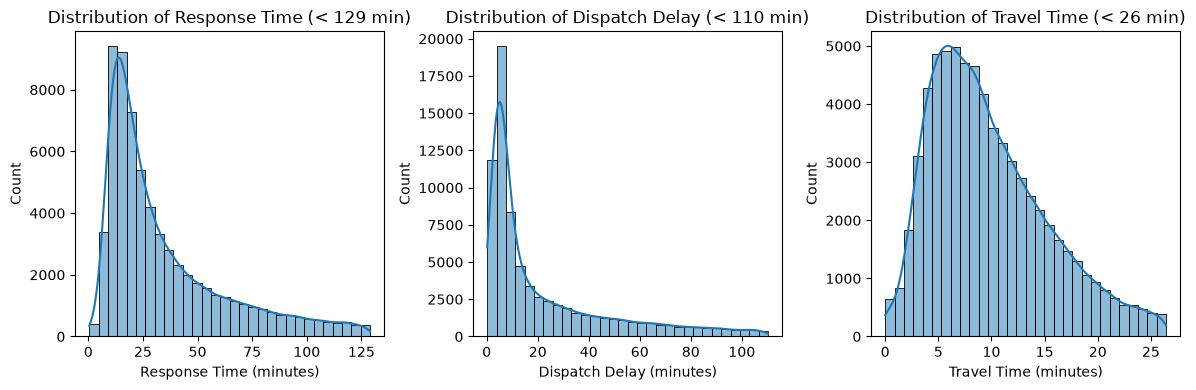

In [19]:
RESPONSE_TIME_THRESHOLD = 128.93
DISPATCH_DELAY_THRESHOLD = 110.25
TRAVEL_TIME_THRESHOLD = 26.43

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.histplot(df[df["response_time"] < RESPONSE_TIME_THRESHOLD]["response_time"].dropna(), bins=30, kde=True)
plt.title(f"Distribution of Response Time (< {RESPONSE_TIME_THRESHOLD:.0f} min)")
plt.xlabel("Response Time (minutes)")
plt.subplot(1, 3, 2)
sns.histplot(df[df["dispatch_delay"] < DISPATCH_DELAY_THRESHOLD]["dispatch_delay"].dropna(), bins=30, kde=True)
plt.title(f"Distribution of Dispatch Delay (< {DISPATCH_DELAY_THRESHOLD:.0f} min)")
plt.xlabel("Dispatch Delay (minutes)")
plt.subplot(1, 3, 3)
sns.histplot(df[df["travel_time"] < TRAVEL_TIME_THRESHOLD]["travel_time"].dropna(), bins=30, kde=True)
plt.title(f"Distribution of Travel Time (< {TRAVEL_TIME_THRESHOLD:.0f} min)")
plt.xlabel("Travel Time (minutes)")
plt.tight_layout()
plt.show()

#### Using the median to find interesting data

The distribution on each column is positively skewed. More importantly, the mean is not representative of the average time in these columns, **therefore we should use the median to get more accurate conclussions**

criticality
E    11.12
D    24.23
B    26.58
A    35.17
C    35.92
O    40.80
Name: response_time, dtype: float64

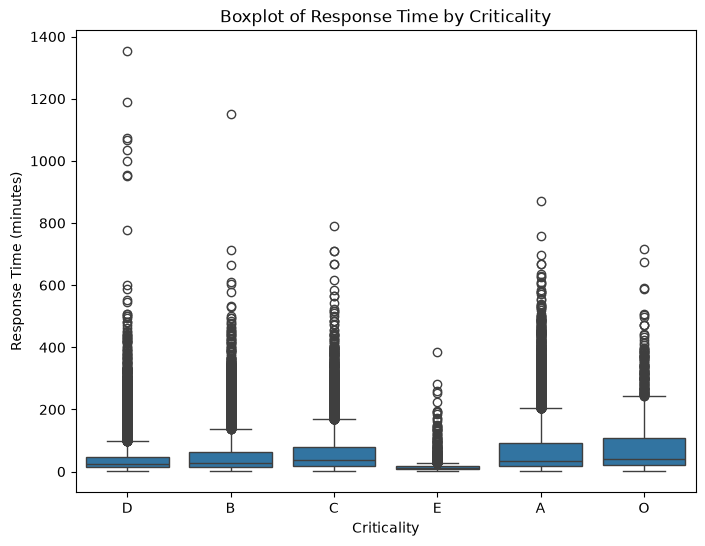

In [20]:
# Crossing response time by criticality using median values
response_by_criticality = df.groupby("criticality")["response_time"].median().round(2).sort_values()
display(response_by_criticality)

# Boxplot of response time by criticality
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="criticality", y="response_time")
plt.title("Boxplot of Response Time by Criticality")
plt.xlabel("Criticality")
plt.ylabel("Response Time (minutes)")
plt.show()

We can observe that highest criticalities get faster response times with **Echo** being the highest with 11.12 minutes, followed by **Delta** with 24.23 minutes; except for **Charlie** criticality which sits below **Bravo** and **Alpha** with 35.92 minutes, 26.58 minutes and 35.17 minutes respectively.

Another interesting aspect we can look at is the response time per station:

In [21]:
# Crossing stations and response times
response_by_station = df.groupby("Station")["response_time"].median().round(2).sort_values()
display(response_by_station)

Station
Dun Laoghaire Fire Station     14.88
Tara Street Fire Station       22.23
North Strand Fire Station      22.54
Donnybrook Fire Station        23.74
Phibsborough Fire Station      24.40
Kilbarrack Fire Station        25.57
Finglas Fire Station           26.95
Rathfarnharm Fire Station      27.24
Blanchardstown Fire Station    27.89
Dolphins Barn Fire Station     27.98
Tallaght Fire Station          32.24
Swords Fire Station            32.45
Balbriggan Fire Station        43.77
Skerries Fire Station          45.01
Name: response_time, dtype: float64

The station with the fastest response time is **Dun Laoghaire** station, with a median of ~15 minutes response time, followed by **Tara Street** with ~22 minutes. The station with the lowest response time is **Skerries**. City stations have a lower reponse times, while rural north-county stations like **Balbriggan** and **Skerries** are at ≈44–45 min, roughly double.

In [22]:
# Crossing response time with station and criticality with their medians
response_df = df.groupby(["Station", "criticality"])["response_time"].median().unstack().round(2)
display(response_df)

criticality,A,B,C,D,E,O
Station,,,,,,
Balbriggan Fire Station,53.58,38.00,66.10,41.68,16.87,50.30
Blanchardstown Fire Station,34.07,26.58,33.72,25.25,11.25,50.08
Dolphins Barn Fire Station,41.02,28.15,35.25,24.26,10.58,50.30
Donnybrook Fire Station,30.59,22.84,28.46,21.29,11.08,32.38
Dun Laoghaire Fire Station,24.50,15.37,58.38,14.48,10.43,23.50
Finglas Fire Station,38.02,25.68,31.80,24.00,10.45,41.82
Kilbarrack Fire Station,26.58,26.78,33.72,24.18,10.95,31.38
North Strand Fire Station,28.15,23.68,28.43,19.65,10.52,30.03
Phibsborough Fire Station,38.25,23.58,34.38,20.62,9.65,34.85


By crossing the station and the criticality on the response time column, we can do multiple observations such as:

1. **Philsborough** Fire Station has the fastest response time to **Echo** incident categories with a median of 9.65 minutes.
2. **Skerries** Fire Station has the slowest response time to **Echo** incident categories, with almost double the amount of time it takes for Philsborough Fire Station.
3. **Dun Laoghaire** Fire Station has the most **Echo** incident categories, and has a low response time of 10.43 minutes making it very efficient in handling high criticality incidents.

#### Calls over time

Getting data from call over time, daily, hourly, weekdays and monthly.

In [23]:
# Mean and sd of calls per day
calls_per_day = df.groupby("Date").size()
mean_calls_per_day = calls_per_day.mean()
std_calls_per_day = calls_per_day.std()

print(f"""
Calls per day:
Mean: {mean_calls_per_day:.2f}
Standard Deviation: {std_calls_per_day:.2f}
""")


Calls per day:
Mean: 228.04
Standard Deviation: 16.59



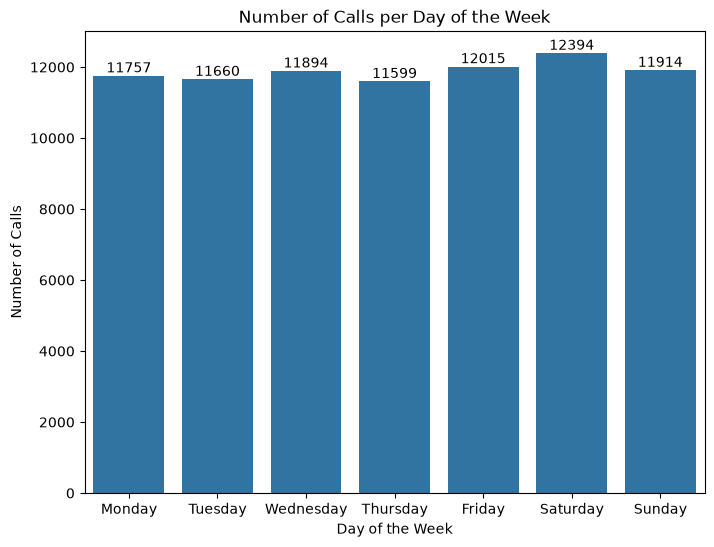

In [24]:
# Count of calls per day of the week
df["day_of_week"] = df["Date"].dt.day_name()
calls_per_day_of_week = df.groupby("day_of_week").size().reindex(
  ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)
plt.figure(figsize=(8, 6))
sns.barplot(x=calls_per_day_of_week.index, y=calls_per_day_of_week.values, )
plt.title("Number of Calls per Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Calls")

for i, value in enumerate(calls_per_day_of_week.values):
    plt.text(i, value, str(value), ha='center', va='bottom')

plt.show()

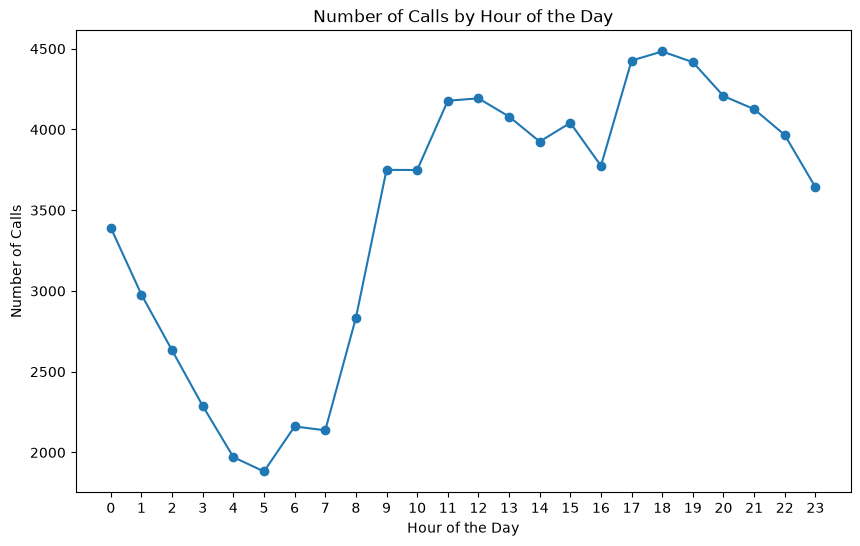

In [25]:
# Count of calls by hour of the day
df["hour_of_day"] = pd.to_datetime(df["TOC"], format="%H:%M:%S").dt.hour
calls_per_hour = df.groupby("hour_of_day").size()
plt.figure(figsize=(10, 6))
plt.plot(calls_per_hour.index, calls_per_hour.values, marker='o')
plt.xticks(ticks=range(0, 24), labels=[hour for hour in range(0, 24)])
plt.title("Number of Calls by Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Calls")
plt.show()

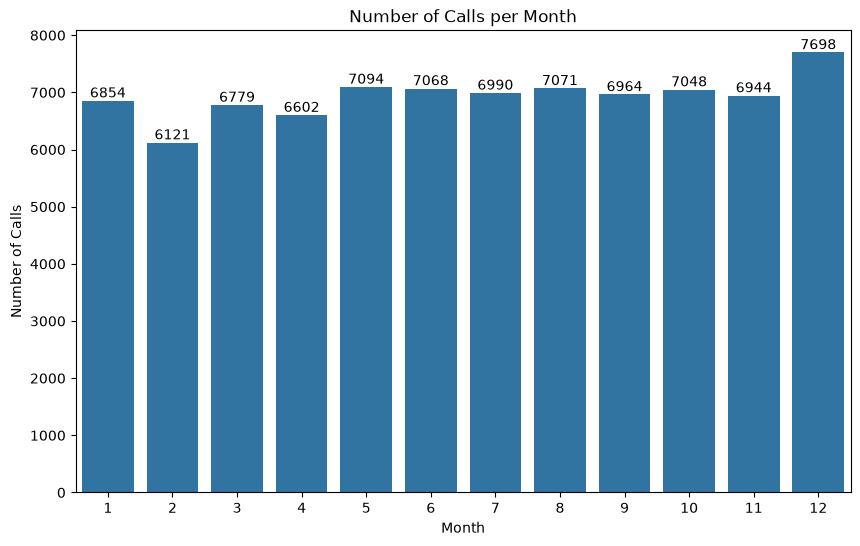

In [26]:
# Number of call per month
df["month"] = df["Date"].dt.month
calls_per_month = df.groupby("month").size()
plt.figure(figsize=(10, 6))
sns.barplot(x=calls_per_month.index, y=calls_per_month.values)
plt.title("Number of Calls per Month")
plt.xlabel("Month")
plt.ylabel("Number of Calls")
for i, value in enumerate(calls_per_month.values):
    plt.text(i, value, str(value), ha='center', va='bottom')
plt.show()

### Plots

**Response time by priority**. We are looking for the slowest times in the highest priority, in order to create an action plan on how to improve those times in the given department.

#### Plot 1

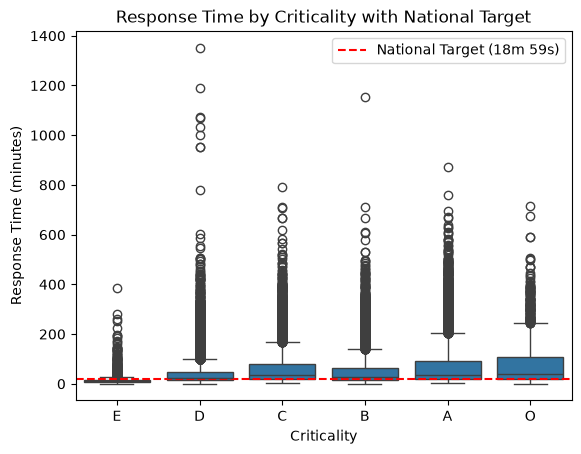

In [27]:
NATIONAL_TARGET = 18 + 59 / 60  # 18 minutes and 59 seconds in minutes
priority_order = list(criticality_values.keys())

sns.boxplot(data=df, x="criticality", y="response_time", order=priority_order)
plt.axhline(NATIONAL_TARGET, color='red', linestyle='--', label='National Target (18m 59s)')
plt.title("Response Time by Criticality with National Target")
plt.xlabel("Criticality")
plt.ylabel("Response Time (minutes)")
plt.legend()
plt.show()

#### Plot 2

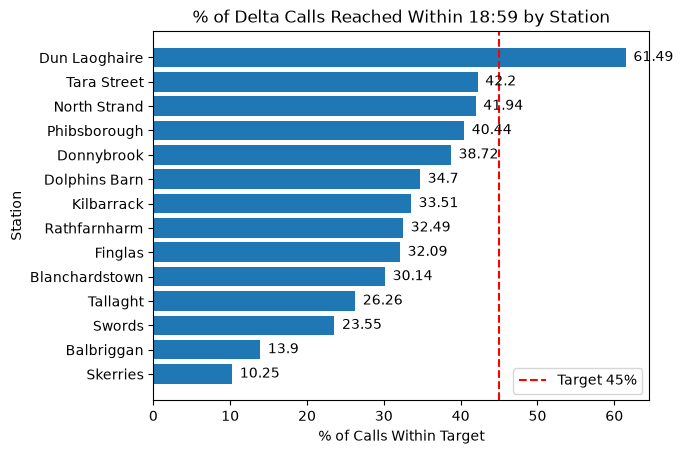

In [28]:
# % of delta calls reached within the national target, by station
delta = df[df["criticality"] == "D"]
within = (delta["response_time"] <= NATIONAL_TARGET).groupby(delta["Station"]).mean().mul(100).round(2).sort_values()
within.index = within.index.str.replace(" Fire Station", "")
plt.barh(within.index, within.values)
plt.axvline(45, color="red", linestyle="--", label="Target 45%")
plt.title("% of Delta Calls Reached Within 18:59 by Station")
plt.xlabel("% of Calls Within Target")
plt.ylabel("Station")
for i, value in enumerate(within.values):
    plt.text(value + 1, i, str(value), va='center')
plt.legend()
plt.show()

**Delta % within national target**, as one of the criterias given by the HSE National Service Plan 2025, which targets 75% of Echo calls and 45% of Delta calls reached within 18:59. HSE now calls these categories *Purple* and *Red*.

#### Plot 3

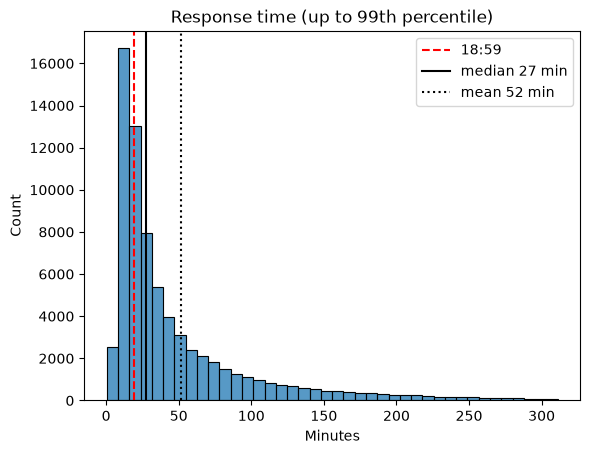

In [29]:
# Shape of the response time
response_time = df["response_time"].dropna()
sns.histplot(response_time[response_time <= response_time.quantile(0.99)], bins=40)
plt.axvline(NATIONAL_TARGET, color="red", linestyle="--", label="18:59")
plt.axvline(response_time.median(), color="black", label=f"median {response_time.median():.0f} min")
plt.axvline(response_time.mean(), color="black", linestyle=":", label=f"mean {response_time.mean():.0f} min")
plt.title("Response time (up to 99th percentile)")
plt.xlabel("Minutes")
plt.legend()
plt.show()

The histogram of the response time show a high positive skew, there are outliers in the data that affect the **mean** directly and show a biased 52 minutes. The **median** on the other hand, is 9 minutes more than the national target, meaning most departments should work on their response time.

#### Plot 4

See above at [Number of Calls by Hour of the Day](#calls-over-time)

## Task 2

### Binomial

For the binomial probabilites, we can use criticality **Echo** and **Delta** calls in one day, and the probability for them to be within the national target of 18:59.

In [40]:
# We code a binomial probability
echo = df[df["criticality"] == "E"]

# Probability of Echo and Delta
p_echo = (echo["response_time"].dropna() <= NATIONAL_TARGET).mean()
p_delta = (delta["response_time"].dropna() <= NATIONAL_TARGET).mean()

# Echo calls per day, counting days with no Echo calls as 0
echo_per_day = echo.groupby("Date").size().reindex(calls_per_day.index, fill_value=0)
n_echo = int(echo_per_day.median())

# Delta calls per day
delta_per_day = delta.groupby("Date").size().reindex(calls_per_day.index, fill_value=0)
n_delta = int(delta_per_day.median())

print(f"""
p (Echo within 18:59): {p_echo:.3f}
Echo calls per day: mean {echo_per_day.mean():.3f}, median {n_echo}

p (Delta within 18:59): {p_delta:.3f}
Delta calls per day: mean {delta_per_day.mean():.3f}, median {n_delta}
""")


p (Echo within 18:59): 0.784
Echo calls per day: mean 5.600, median 6

p (Delta within 18:59): 0.385
Delta calls per day: mean 109.732, median 109



In [31]:
# Plot the binomial as a function
def plot_binomial(n, p, label, normal_curve = False):
    k = np.arange(0, n + 1)
    mean, sd = n * p, np.sqrt(n * p * (1 - p))
    probs = binom.pmf(k, n, p)
    plt.bar(k, probs)
    plt.title(f"{label} Calls Reached Within 18:59 (n = {n}, p = {p:.3f})")
    plt.xlabel("Calls Reached Within 18:59")
    plt.ylabel("Probability")

    if normal_curve:
        x = np.linspace(0, n, 500)
        plt.plot(x, norm.pdf(x, mean, sd), color="red", label="Normal approximation")
        plt.legend()

    return k, probs

#### Echo Calls

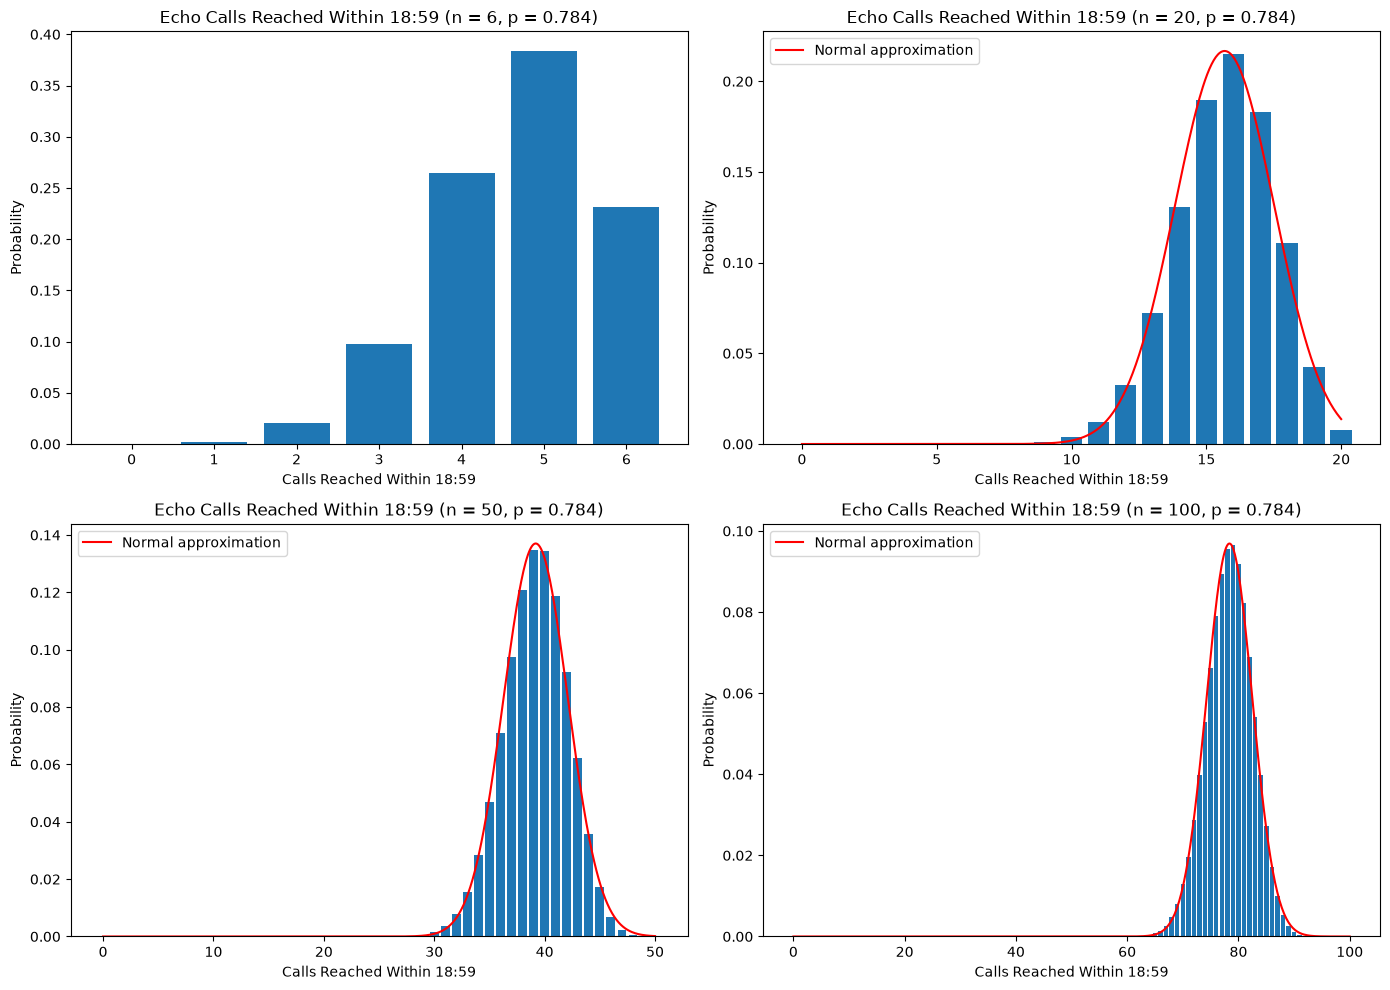

P(all 6 reached in time) = 0.232
P(at least one late) = 0.768
P(at least 75% in time) = 0.616


In [ ]:
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plot_binomial(6, p_echo, "Echo")
plt.subplot(2, 2, 2)
plot_binomial(20, p_echo, "Echo", True)
plt.subplot(2, 2, 3)
plot_binomial(50, p_echo, "Echo", True)
plt.subplot(2, 2, 4)
plot_binomial(100, p_echo, "Echo", True)
plt.tight_layout()
plt.show()

print(f"p(all {n_echo} reached in time) = {binom.pmf(n_echo, n_echo, p_echo):.3f}")
print(f"p(at least one late) = {1 - binom.pmf(n_echo, n_echo, p_echo):.3f}")
print(f"p(at least 75% in time) = {binom.sf(np.ceil(0.75 * n_echo) - 1, n_echo, p_echo):.3f}")

**n = 6:** With the graph we can see the distribution is negatively skewed: this means that the probabilty of reaching an **Echo** call in the national target is high (p is high = 0.784). Most likely a day: 5 out of 6 cardiac-arrest calls are going to be reached in time. The chance of a "perfect" day (all calls reached below the national target) is of 23.2%, so on 77% of days at least one cardiac-arrest patient waits longer than the 18 minutes.

**n = 20:** The curve doesn't really fit. The bars lean right and the right-hand tail is cut off at 20, while the Normal stays symmetric and runs past 20 into calls that can't happen. Here n(1 - p) = 4.2.

**n = 50**: the curve sits almost exactly on the bars. Here $ n(1 − p) = 10.8 $, so the condition is just met and the curve fits.

**n = 100**: The dfistribution is normal.

#### Intepretation

As n grows, the shape becomes a bell and the red normal curve starts to fit. With enough calls, the Binomial can be replaced by the simpler Normal distribution. The national target of reaching 75% of Echo calls grows as the sample becomes bigger, fitting into an 83% chance with n = 100. Echo's true rate is above its target, so a larger sample meakes metting the target more likely.

#### Delta Calls

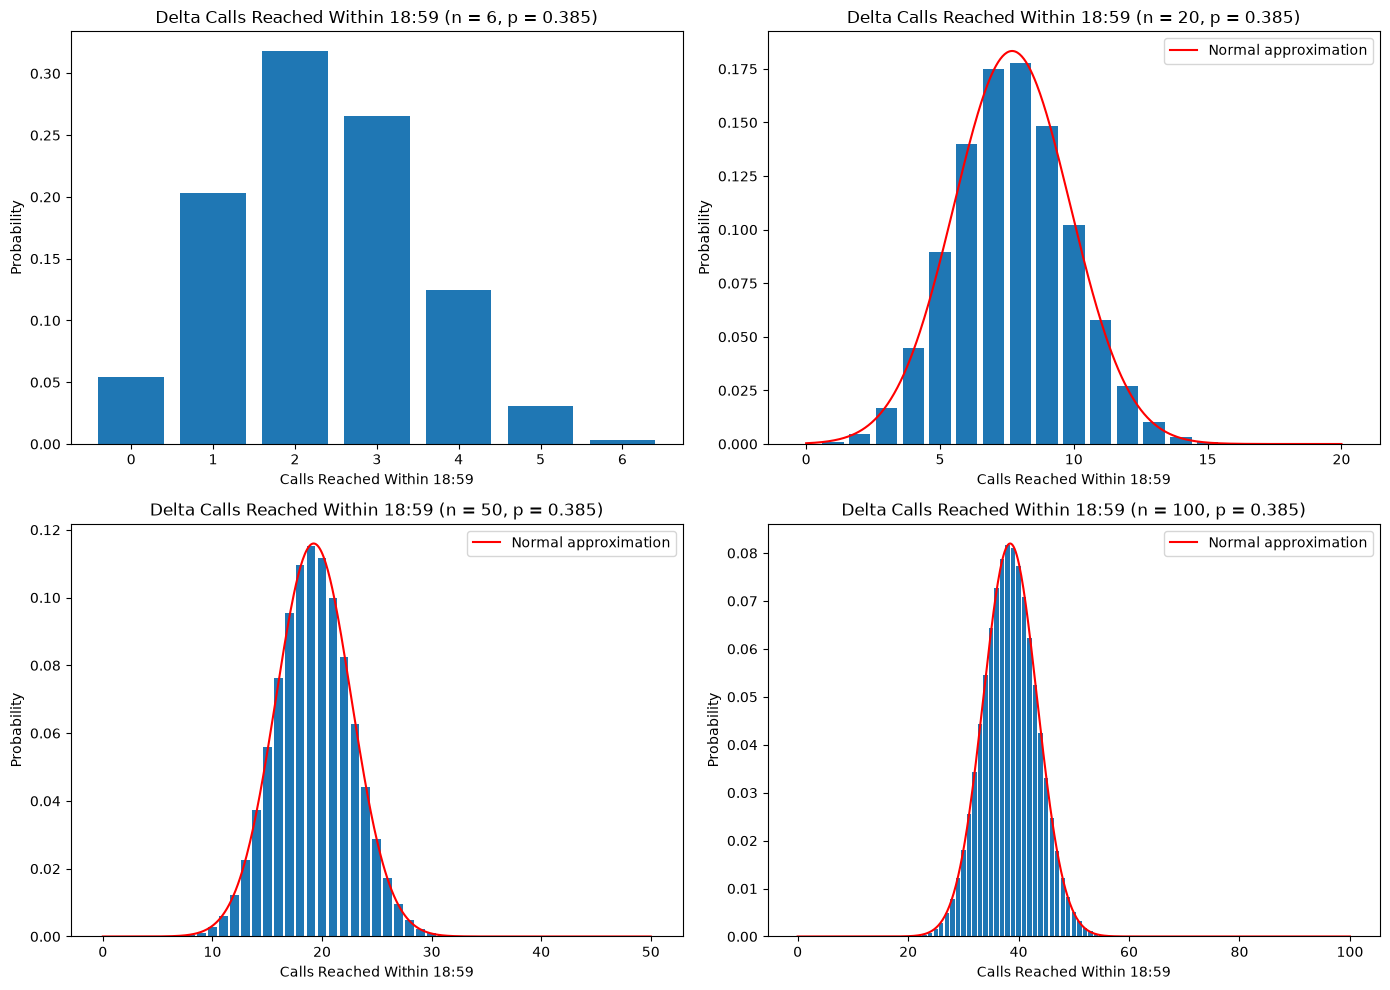

P(all 109 reached in time) = 0.000
P(at least one late) = 1.000
P(at least 45% in time) = 0.069


In [44]:
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plot_binomial(6, p_delta, "Delta")
plt.subplot(2, 2, 2)
plot_binomial(20, p_delta, "Delta", True)
plt.subplot(2, 2, 3)
plot_binomial(50, p_delta, "Delta", True)
plt.subplot(2, 2, 4)
plot_binomial(100, p_delta, "Delta", True)
plt.tight_layout()
plt.show()

print(f"P(all {n_delta} reached in time) = {binom.pmf(n_delta, n_delta, p_delta):.3f}")
print(f"P(at least one late) = {1 - binom.pmf(n_delta, n_delta, p_delta):.3f}")
print(f"P(at least 45% in time) = {binom.sf(np.ceil(0.45 * n_delta) - 1, n_delta, p_delta):.3f}")

In [41]:
rows = []
for n in [6, 20, 50, 100]:
    low, high = binom.ppf([0.025, 0.975], n, p_echo)   # calls reached in time at the 2.5th and 97.5th percentiles
    k_echo = np.ceil(0.75 * n)                         # calls needed to reach 75%
    k_delta = np.ceil(0.45 * n)                        # calls needed to reach 45%
    rows.append({
        "n": n,
        "Echo 95% range": f"{low / n:.0%} - {high / n:.0%}",
        "P(Echo >= 75%)": binom.sf(k_echo - 1, n, p_echo),
        "P(Delta >= 45%)": binom.sf(k_delta - 1, n, p_delta),
    })
pd.DataFrame(rows).round(3)

,n,Echo 95% range,P(Echo >= 75%),P(Delta >= 45%)
0,6,50% - 100%,0.616,0.424
1,20,60% - 95%,0.748,0.350
2,50,66% - 90%,0.726,0.171
3,100,70% - 86%,0.828,0.108


### Poisson

## Task 3

## Task 4